In [72]:
import pandas as pd
import numpy as np
from statsmodels.tsa.filters.hp_filter import hpfilter
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})

In [73]:
# indlæs og tilpas portugal
por = pd.read_csv("data/namq_10_gdp__custom_23596981_linear_2_0.csv")
por.rename(columns={
    'National accounts indicator (ESA 2010)':'indicator',
    'geo':'country_code',
    'TIME_PERIOD':'time_period',
    'OBS_VALUE':'obs_value'
}, inplace=True)

# udvælg kolopnner
por = por[['indicator','time_period','country_code','obs_value']]
por['indicator'] = por['indicator'].replace({
    'Gross domestic product at market prices': 'GDP',
    'Final consumption expenditure': 'Consumption',
    'Gross capital formation': 'Investment'
})

# filtrer efter portugal
por = por.loc[por['country_code'] == 'PT']
por['time_period'] = por['time_period'].str.replace('-', '') 
por['time_period'] = pd.PeriodIndex(por['time_period'], freq='Q').to_timestamp()
por

,indicator,time_period,country_code,obs_value
4449,GDP,1995-01-01,PT,35271.3
4450,GDP,1995-04-01,PT,35677.9
4451,GDP,1995-07-01,PT,35843.0
4452,GDP,1995-10-01,PT,36091.2
4453,GDP,1996-01-01,PT,36329.3
...,...,...,...,...
15115,Investment,2025-04-01,PT,11358.8
15116,Investment,2025-07-01,PT,11679.7
15117,Investment,2025-10-01,PT,11508.2
15118,Investment,2026-01-01,PT,12294.0


por.unique()

In [74]:
# indlæs og tilpas US data
us_gdp = pd.read_csv('data/GDPC1.csv')
us_gdp['indicator'] = 'GDP'
us_gdp.rename(columns={'GDPC1':'obs_value'}, inplace=True)

us_inv_saving = pd.read_csv('data/GPDIC1.csv')
us_inv_saving['indicator'] = 'Investment'
us_inv_saving.rename(columns={'GPDIC1':'obs_value'}, inplace=True)

us_cons = pd.read_csv('data/PCECC96.csv')
us_cons['indicator'] = 'Consumption'
us_cons.rename(columns={'PCECC96':'obs_value'}, inplace=True)

us = pd.concat((us_gdp,us_inv_saving,us_cons))
us.rename(columns={'observation_date':'time_period'}, inplace=True)
us['country_code'] = 'US'
us['time_period'] = pd.PeriodIndex(us['time_period'], freq='Q').to_timestamp()
us

,time_period,obs_value,indicator,country_code
0,1947-01-01,2182.681,GDP,US
1,1947-04-01,2176.892,GDP,US
2,1947-07-01,2172.432,GDP,US
3,1947-10-01,2206.452,GDP,US
4,1948-01-01,2239.682,GDP,US
...,...,...,...,...
313,2025-04-01,16378.319,Consumption,US
314,2025-07-01,16526.176,Consumption,US
315,2025-10-01,16604.582,Consumption,US
316,2026-01-01,16634.157,Consumption,US


In [76]:
# sammensæt landedata til et datasæt: tilpas tidsperioden, så begge lande har samme periode
df = pd.concat((us,por))
df = df.loc[df['time_period'] >= pd.Timestamp('1995-01-01')]
df.to_csv('output/processed_NA.csv', index=False)

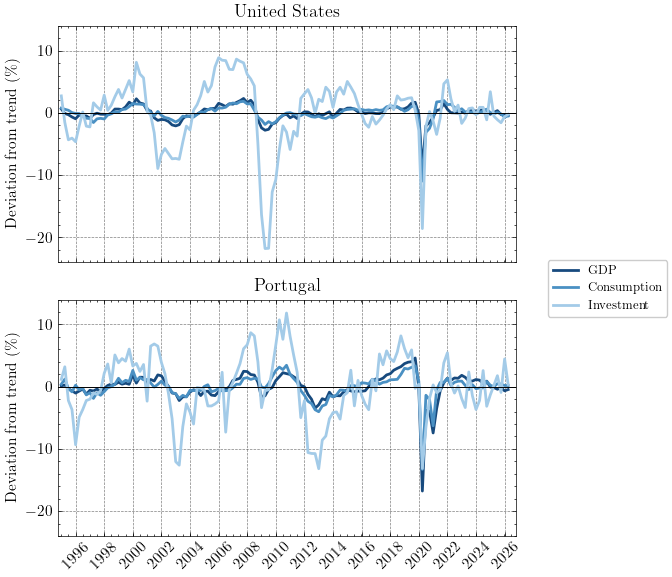

In [77]:
df = pd.read_csv('output/processed_NA.csv')
df['time_period'] = pd.to_datetime(df['time_period'])
df = df.sort_values(['country_code', 'indicator', 'time_period']).copy()

for (country, indicator), idx in df.groupby(['country_code', 'indicator']).groups.items():
    y = np.log(df.loc[idx, 'obs_value'])

    cycle, trend = hpfilter(y, lamb=1600)

    df.loc[idx, 'hp_cycle'] = cycle * 100
    df.loc[idx, 'hp_trend'] = np.exp(trend)

colors = ['#174A7E', '#4A90C3', '#A3CBE8']
indicators = ['GDP', 'Consumption', 'Investment']

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

i = 0
for ax, (country, name) in zip(axes, [('US', 'United States'), ('PT', 'Portugal')]):

    for indicator, color in zip(indicators, colors):
        sub = df.loc[(df.country_code == country) & (df.indicator == indicator)]
        ax.plot(sub.time_period, sub.hp_cycle, label=indicator, color=color, lw=2)

    ax.axhline(0, color='black', linewidth=0.7)
    ax.set_title(name)
    ax.set_ylabel('Deviation from trend (\%)')
    ax.set_ylim(-24, 14)

axes[-1].set_xlim(pd.Timestamp('1994-10-01'), pd.Timestamp('2026-10-31'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].tick_params(axis='x', rotation=45)

# Remove ax.legend() and the variable i from your loop
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc='center left',
    bbox_to_anchor=(0.79, 0.5),
    frameon=True
)

plt.tight_layout(rect=[0, 0, 0.78, 1])
plt.savefig("output/business_cycles_us_pl.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [78]:
df.to_csv('output/processed_NA_with_HP_cycle.csv',index=False)

In [79]:
# beregn standardafvigelser for serier
results = []

for (country, indicator), idx in df.groupby(['country_code', 'indicator']).groups.items():
    y = np.log(df.loc[idx, 'obs_value'])
    cycle, trend = hpfilter(y, lamb=1600)

    results.append({
        'Country': country,
        'Indicator': indicator,
        'Std. dev.': np.std(cycle)
    })

# nemt aflæselig tabel
std_table = pd.DataFrame(results).pivot(
    index='Country',
    columns='Indicator',
    values='Std. dev.'
)

std_table.round(4)

Indicator,Consumption,GDP,Investment
Country,,,
PT,0.0189,0.0227,0.0506
US,0.0135,0.0128,0.0545


In [80]:
# sigma_c = 1/sqrt(12) ((1+sigma_eps)-(1-sigma_eps)) = (2*sigma_eps)/sqrt(12) 
# <=>
# sigma_eps = sqrt(12) / 2 * sigma_c 
def sigma_eps(sigma_c):
    return sigma_c * np.sqrt(12) / 2

std_table.loc['PT','sigma_exp'] = sigma_eps(std_table.loc['PT', 'Consumption'])
std_table.loc['US','sigma_exp'] = sigma_eps(std_table.loc['US', 'Consumption'])
std_table.round(4)

Indicator,Consumption,GDP,Investment,sigma_exp
Country,,,,
PT,0.0189,0.0227,0.0506,0.0327
US,0.0135,0.0128,0.0545,0.0234


In [81]:
def lambda_crra(eps, gamma=1.99):
    E = ((1+eps)**(2-gamma) - (1-eps)**(2-gamma)) / (2*eps*(2-gamma))
    return 1 - E**(1/(1-gamma))

# beregn lambda for hvert land
eps_low  = sigma_eps(std_table['Consumption'])
eps_high = sigma_eps(std_table['Consumption'])

std_table['Lambda low RA (%)']  = lambda_crra(eps_low) * 100
std_table['Lambda high RA (%)'] = lambda_crra(eps_high, gamma=4.0) * 100

std_table.round(4)

Indicator,Consumption,GDP,Investment,sigma_exp,Lambda low RA (%),Lambda high RA (%)
Country,,,,,,
PT,0.0189,0.0227,0.0506,0.0327,0.0355,0.0714
US,0.0135,0.0128,0.0545,0.0234,0.0182,0.0365


In [82]:
def lambda_unemployment(gamma):
    "gamma må ikke være 1"

    return 1 - (0.95 * 1.02**(1-gamma) + 0.05 * 0.62**(1-gamma))**(1/(1-gamma))

print(f"Forbruger er villig til at nedjustere forbrug med   {lambda_unemployment(2)*100:.4f}%   for at undgå arbejdsløshedsrisiko")

Forbruger er villig til at nedjustere forbrug med   1.1875%   for at undgå arbejdsløshedsrisiko
